# Etapa A — Binário: *Myotis lavali* × resto

"Resto" = as outras 7 espécies do recorte. Classes de tamanho parecido
(~7.284 × ~6.124), o caso mais fácil de propósito — isola a forma da
fronteira de decisão (linear × não linear) sem o efeito extra de
desbalanceamento, que só entra na Etapa B.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

np.random.seed(42)
torch.manual_seed(42)

dados = np.load("../dados_processados/etapa2.npz", allow_pickle=True)
list(dados.keys())

['X_simples',
 'y_simples',
 'colunas_simples',
 'pos_treino_simples',
 'pos_val_simples',
 'pos_teste_simples',
 'media_simples',
 'desvio_simples',
 'X_completa',
 'y_completa',
 'colunas_completa',
 'pos_treino_completa',
 'pos_val_completa',
 'pos_teste_completa',
 'media_completa',
 'desvio_completa',
 'X_completa_com_tipo',
 'colunas_completa_com_tipo',
 'media_completa_com_tipo',
 'desvio_completa_com_tipo',
 'especies_recorte']

## Rótulo binário e conjuntos

Usando a representação **simples** (é com ela que a Etapa A começa, por
acordo do plano). Rótulo: 1 = `Myotis_lavali`, 0 = qualquer outra espécie do
recorte. A divisão treino/val/teste já foi salva na Etapa 2 — só recarregar.

In [2]:
X = dados["X_simples"]
y_especie = dados["y_simples"]
pos_treino = dados["pos_treino_simples"]
pos_val = dados["pos_val_simples"]
pos_teste = dados["pos_teste_simples"]

y_bin = (y_especie == "Myotis_lavali").astype(np.float32)

X_treino, y_treino = X[pos_treino].astype(np.float32), y_bin[pos_treino]
X_val, y_val = X[pos_val].astype(np.float32), y_bin[pos_val]
X_teste, y_teste = X[pos_teste].astype(np.float32), y_bin[pos_teste]

print(f"Treino: {len(y_treino)} ({y_treino.mean()*100:.1f}% lavali)")
print(f"Validação: {len(y_val)} ({y_val.mean()*100:.1f}% lavali)")
print(f"Teste: {len(y_teste)} ({y_teste.mean()*100:.1f}% lavali) — não olhar ainda")

Treino: 9386 (54.3% lavali)
Validação: 2011 (54.4% lavali)
Teste: 2011 (54.3% lavali) — não olhar ainda


## A1 — Modelo linear de referência (regressão logística)

Um único neurônio: combinação linear das 5 entradas + sigmoide na saída.
Matematicamente é a regressão logística (Slides Rosenblatt e Regressão
Logística) — `nn.Sequential` com uma camada `Linear(5, 1)` e `Sigmoid()`,
seguindo o molde do exemplo do curso: `nn.Module`, `DataLoader` com
mini-batch, alternando `model.train()`/`model.eval()`.

In [3]:
class RegressaoLogistica(nn.Module):
    def __init__(self, n_entradas):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(n_entradas, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.rede(x)


modelo_a1 = RegressaoLogistica(X_treino.shape[1])
modelo_a1

RegressaoLogistica(
  (rede): Sequential(
    (0): Linear(in_features=5, out_features=1, bias=True)
    (1): Sigmoid()
  )
)

### Treinando A1

`DataLoader` com mini-batch, `BCELoss` (entropia cruzada binária — a função
custo correta pra regressão logística), `SGD`, alternando `model.train()` /
`model.eval()`, acompanhando a perda de treino e validação por época.

In [4]:
from torch.utils.data import TensorDataset, DataLoader
import copy

t_X_treino = torch.from_numpy(X_treino)
t_y_treino = torch.from_numpy(y_treino).unsqueeze(1)
t_X_val = torch.from_numpy(X_val)
t_y_val = torch.from_numpy(y_val).unsqueeze(1)

loader_treino = DataLoader(TensorDataset(t_X_treino, t_y_treino), batch_size=64, shuffle=True)

torch.manual_seed(42)
modelo_a1 = RegressaoLogistica(X_treino.shape[1])

criterio = nn.BCELoss()
otimizador = torch.optim.SGD(modelo_a1.parameters(), lr=0.1)

N_EPOCAS = 400
perdas_treino, perdas_val = [], []
melhor_perda_val = float("inf")
melhores_pesos_a1 = None

for epoca in range(N_EPOCAS):
    modelo_a1.train()
    perda_acumulada = 0.0
    for xb, yb in loader_treino:
        otimizador.zero_grad()
        saida = modelo_a1(xb)
        perda = criterio(saida, yb)
        perda.backward()
        otimizador.step()
        perda_acumulada += perda.item() * len(xb)
    perdas_treino.append(perda_acumulada / len(t_X_treino))

    modelo_a1.eval()
    with torch.no_grad():
        perda_val = criterio(modelo_a1(t_X_val), t_y_val).item()
    perdas_val.append(perda_val)

    if perda_val < melhor_perda_val:
        melhor_perda_val = perda_val
        melhores_pesos_a1 = copy.deepcopy(modelo_a1.state_dict())

modelo_a1.load_state_dict(melhores_pesos_a1)  # volta pro ponto de mínimo da validação

print(f"Última época — treino: {perdas_treino[-1]:.4f}, validação: {perdas_val[-1]:.4f}")
print(f"Melhor perda de validação: {min(perdas_val):.4f} na época {np.argmin(perdas_val)+1} (pesos restaurados)")

Última época — treino: 0.2204, validação: 0.2375
Melhor perda de validação: 0.2373 na época 285 (pesos restaurados)


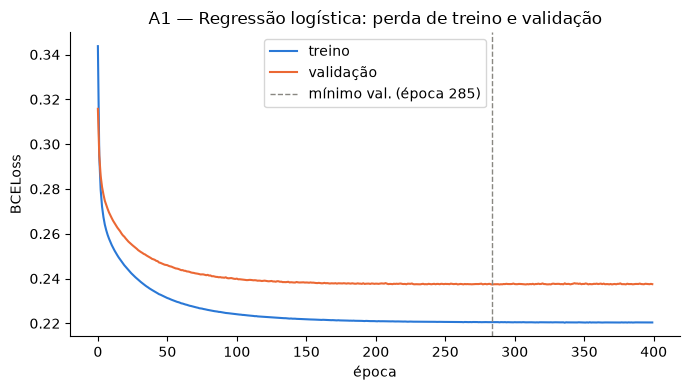

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(perdas_treino, label="treino", color="#2a78d6")
ax.plot(perdas_val, label="validação", color="#eb6834")
ax.axvline(np.argmin(perdas_val), color="#898781", linestyle="--", linewidth=1,
           label=f"mínimo val. (época {np.argmin(perdas_val)+1})")
ax.set_xlabel("época")
ax.set_ylabel("BCELoss")
ax.set_title("A1 — Regressão logística: perda de treino e validação")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

Convergiu por volta da época 150, com mínimo de validação na época 285. A
diferença pequena entre treino e validação é esperada — modelo linear, poucos
parâmetros, sem "poder" de decorar o treino. Como o critério é parar no
mínimo da validação (não na última época), preciso guardar os pesos daquele
ponto específico, não os do fim do treino.

## A2 — MLP no molde exato do exemplo do curso

Seguindo `ap_exemplo_pytorch`: ativação `Tanh` em todas as camadas (inclusive
a saída), rótulos em `{-1, +1}` (não `{0, 1}`) porque a saída da `Tanh` vive
nesse intervalo, `MSELoss`, `SGD`. Uma camada oculta pequena por enquanto — o
tamanho ideal é assunto da Etapa D, aqui só queremos o molde certo.

In [6]:
class MLP_Tanh(nn.Module):
    def __init__(self, n_entradas, n_ocultos=8):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(n_entradas, n_ocultos),
            nn.Tanh(),
            nn.Linear(n_ocultos, 1),
            nn.Tanh(),
        )

    def forward(self, x):
        return self.rede(x)


# rótulos em {-1, +1} para bater com a faixa da Tanh de saída
y_pm1_treino = 2 * y_treino - 1
y_pm1_val = 2 * y_val - 1

t_y_pm1_treino = torch.from_numpy(y_pm1_treino).unsqueeze(1)
t_y_pm1_val = torch.from_numpy(y_pm1_val).unsqueeze(1)

torch.manual_seed(42)
modelo_a2 = MLP_Tanh(X_treino.shape[1])
modelo_a2

MLP_Tanh(
  (rede): Sequential(
    (0): Linear(in_features=5, out_features=8, bias=True)
    (1): Tanh()
    (2): Linear(in_features=8, out_features=1, bias=True)
    (3): Tanh()
  )
)

In [7]:
loader_treino_a2 = DataLoader(TensorDataset(t_X_treino, t_y_pm1_treino), batch_size=64, shuffle=True)

criterio_a2 = nn.MSELoss()
otimizador_a2 = torch.optim.SGD(modelo_a2.parameters(), lr=0.1)

N_EPOCAS = 400
perdas_treino_a2, perdas_val_a2 = [], []
melhor_perda_val_a2 = float("inf")
melhores_pesos_a2 = None

for epoca in range(N_EPOCAS):
    modelo_a2.train()
    perda_acumulada = 0.0
    for xb, yb in loader_treino_a2:
        otimizador_a2.zero_grad()
        saida = modelo_a2(xb)
        perda = criterio_a2(saida, yb)
        perda.backward()
        otimizador_a2.step()
        perda_acumulada += perda.item() * len(xb)
    perdas_treino_a2.append(perda_acumulada / len(t_X_treino))

    modelo_a2.eval()
    with torch.no_grad():
        perda_val = criterio_a2(modelo_a2(t_X_val), t_y_pm1_val).item()
    perdas_val_a2.append(perda_val)

    if perda_val < melhor_perda_val_a2:
        melhor_perda_val_a2 = perda_val
        melhores_pesos_a2 = copy.deepcopy(modelo_a2.state_dict())

modelo_a2.load_state_dict(melhores_pesos_a2)

print(f"Última época — treino: {perdas_treino_a2[-1]:.4f}, validação: {perdas_val_a2[-1]:.4f}")
print(f"Melhor perda de validação: {min(perdas_val_a2):.4f} na época {np.argmin(perdas_val_a2)+1} (pesos restaurados)")

Última época — treino: 0.0384, validação: 0.0572
Melhor perda de validação: 0.0556 na época 390 (pesos restaurados)


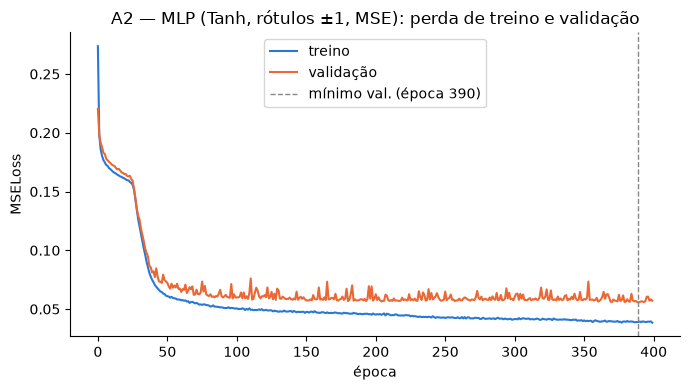

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(perdas_treino_a2, label="treino", color="#2a78d6")
ax.plot(perdas_val_a2, label="validação", color="#eb6834")
ax.axvline(np.argmin(perdas_val_a2), color="#898781", linestyle="--", linewidth=1,
           label=f"mínimo val. (época {np.argmin(perdas_val_a2)+1})")
ax.set_xlabel("época")
ax.set_ylabel("MSELoss")
ax.set_title("A2 — MLP (Tanh, rótulos ±1, MSE): perda de treino e validação")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## A3 — Mesma MLP com as melhorias do Slides_5

Mesma arquitetura (1 camada oculta, `Tanh`), mas troca na saída: **sigmoide**
em vez de `Tanh` (volta pra rótulos `{0, 1}`), **entropia cruzada binária**
em vez de MSE, **Adam** em vez de SGD puro. Só isso muda — mantém tudo o
resto igual ao A2 pra comparação ser justa.

In [9]:
class MLP_Sigmoide(nn.Module):
    def __init__(self, n_entradas, n_ocultos=8):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(n_entradas, n_ocultos),
            nn.Tanh(),
            nn.Linear(n_ocultos, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.rede(x)


torch.manual_seed(42)
modelo_a3 = MLP_Sigmoide(X_treino.shape[1])

loader_treino_a3 = DataLoader(TensorDataset(t_X_treino, t_y_treino), batch_size=64, shuffle=True)

criterio_a3 = nn.BCELoss()
otimizador_a3 = torch.optim.Adam(modelo_a3.parameters(), lr=0.01)

N_EPOCAS = 400
perdas_treino_a3, perdas_val_a3 = [], []
melhor_perda_val_a3 = float("inf")
melhores_pesos_a3 = None

for epoca in range(N_EPOCAS):
    modelo_a3.train()
    perda_acumulada = 0.0
    for xb, yb in loader_treino_a3:
        otimizador_a3.zero_grad()
        saida = modelo_a3(xb)
        perda = criterio_a3(saida, yb)
        perda.backward()
        otimizador_a3.step()
        perda_acumulada += perda.item() * len(xb)
    perdas_treino_a3.append(perda_acumulada / len(t_X_treino))

    modelo_a3.eval()
    with torch.no_grad():
        perda_val = criterio_a3(modelo_a3(t_X_val), t_y_val).item()
    perdas_val_a3.append(perda_val)

    if perda_val < melhor_perda_val_a3:
        melhor_perda_val_a3 = perda_val
        melhores_pesos_a3 = copy.deepcopy(modelo_a3.state_dict())

modelo_a3.load_state_dict(melhores_pesos_a3)

print(f"Última época — treino: {perdas_treino_a3[-1]:.4f}, validação: {perdas_val_a3[-1]:.4f}")
print(f"Melhor perda de validação: {min(perdas_val_a3):.4f} na época {np.argmin(perdas_val_a3)+1} (pesos restaurados)")

Última época — treino: 0.0458, validação: 0.0583
Melhor perda de validação: 0.0571 na época 185 (pesos restaurados)


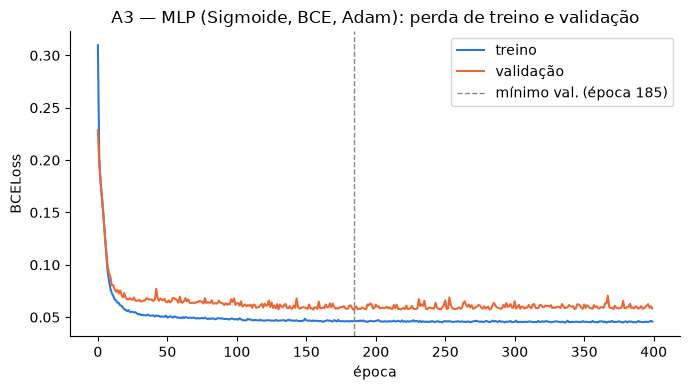

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(perdas_treino_a3, label="treino", color="#2a78d6")
ax.plot(perdas_val_a3, label="validação", color="#eb6834")
ax.axvline(np.argmin(perdas_val_a3), color="#898781", linestyle="--", linewidth=1,
           label=f"mínimo val. (época {np.argmin(perdas_val_a3)+1})")
ax.set_xlabel("época")
ax.set_ylabel("BCELoss")
ax.set_title("A3 — MLP (Sigmoide, BCE, Adam): perda de treino e validação")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Métricas do Slides_6 — calculadas à mão a partir da matriz de confusão

Usando o conjunto de **validação** (não o teste, que só entra na Etapa E).
Matriz de confusão: `TP` (= VP nos slides: previu lavali, era lavali), `FP`
(previu lavali, era outra espécie), `TN` (= VN: previu resto, era resto), `FN`
(previu resto, era lavali). Threshold padrão 0,5 na probabilidade de saída.

Fórmulas conferidas contra o Slides_6 (acurácia, precisão, sensibilidade,
especificidade, F1, MCC, ROC). Na matriz desenhada, seguimos a orientação dos
slides: **linhas = previsto, colunas = verdadeiro** (o scikit-learn usa a
transposta). Convenções que os slides não trazem: AUC pela regra do trapézio e
MCC = 0 quando o denominador é zero.

In [11]:
def matriz_confusao(y_real, y_prob, limiar=0.5):
    y_pred = (y_prob >= limiar).astype(int)
    tp = np.sum((y_pred == 1) & (y_real == 1))
    fp = np.sum((y_pred == 1) & (y_real == 0))
    tn = np.sum((y_pred == 0) & (y_real == 0))
    fn = np.sum((y_pred == 0) & (y_real == 1))
    return tp, fp, tn, fn


def metricas_da_matriz(tp, fp, tn, fn):
    acuracia = (tp + tn) / (tp + fp + tn + fn)
    precisao = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    sensibilidade = tp / (tp + fn) if (tp + fn) > 0 else 0.0  # recall / TPR
    especificidade = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1 = 2 * precisao * sensibilidade / (precisao + sensibilidade) if (precisao + sensibilidade) > 0 else 0.0

    # coeficiente de Matthews
    numerador = (tp * tn) - (fp * fn)
    denominador = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    mcc = numerador / denominador if denominador > 0 else 0.0

    return {
        "acurácia": acuracia, "precisão": precisao, "sensibilidade": sensibilidade,
        "especificidade": especificidade, "F1": f1, "MCC": mcc,
    }


# probabilidades de saída no conjunto de validação
modelo_a1.eval()
modelo_a2.eval()
modelo_a3.eval()
with torch.no_grad():
    prob_a1_val = modelo_a1(t_X_val).numpy().flatten()
    # A2 sai em [-1, 1] (Tanh); (saida + 1) / 2 leva pra [0, 1] sem mudar a ordem,
    # então o limiar 0,5 aqui é o limiar 0 da Tanh e a ROC não muda
    prob_a2_val = (modelo_a2(t_X_val).numpy().flatten() + 1) / 2
    prob_a3_val = modelo_a3(t_X_val).numpy().flatten()

tp1, fp1, tn1, fn1 = matriz_confusao(y_val, prob_a1_val)
tp2, fp2, tn2, fn2 = matriz_confusao(y_val, prob_a2_val)
tp3, fp3, tn3, fn3 = matriz_confusao(y_val, prob_a3_val)

print("Matriz de confusão A1:")
print(f"  TP={tp1}  FP={fp1}")
print(f"  FN={fn1}  TN={tn1}")
print("\nMatriz de confusão A2:")
print(f"  TP={tp2}  FP={fp2}")
print(f"  FN={fn2}  TN={tn2}")
print("\nMatriz de confusão A3:")
print(f"  TP={tp3}  FP={fp3}")
print(f"  FN={fn3}  TN={tn3}")

# checagem: A2 e A3 dão a mesma matriz por coincidência ou são o mesmo modelo?
n_disc = int(((prob_a2_val >= 0.5) != (prob_a3_val >= 0.5)).sum())
print()
print("A2 e A3 discordam em", n_disc, "gravações; diferença máxima entre as saídas:", float(np.abs(prob_a2_val - prob_a3_val).max()))


Matriz de confusão A1:
  TP=1077  FP=102
  FN=16  TN=816

Matriz de confusão A2:
  TP=1078  FP=17
  FN=15  TN=901

Matriz de confusão A3:
  TP=1078  FP=17
  FN=15  TN=901

A2 e A3 discordam em 8 gravações; diferença máxima entre as saídas: 0.8511252999305725


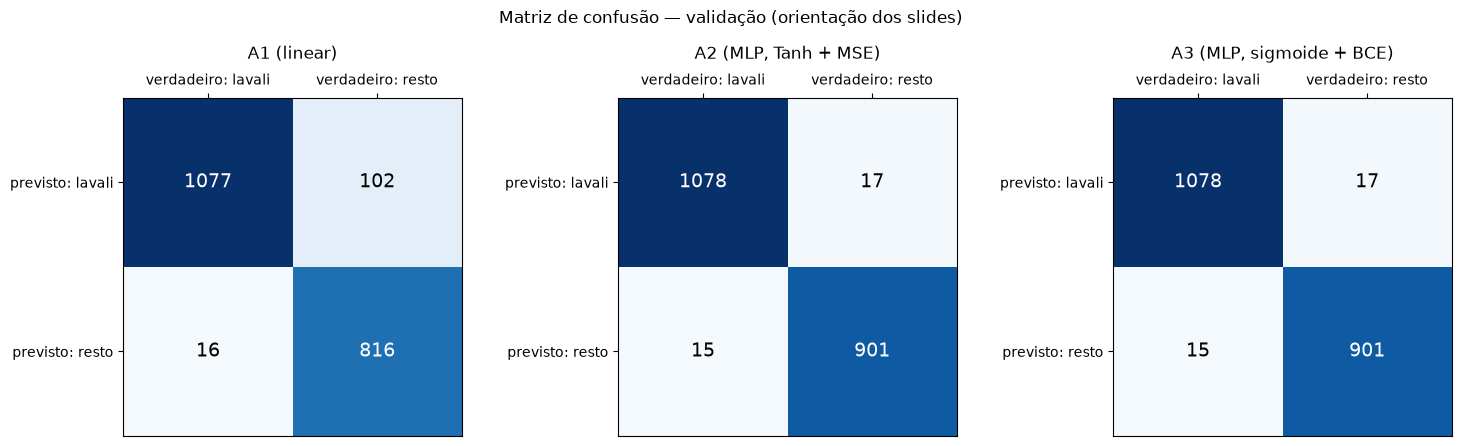

In [12]:
def plota_matriz_confusao(ax, tp, fp, tn, fn, titulo):
    # orientação dos slides (Slides_6, p. 5): linha = PREVISTO, coluna = VERDADEIRO
    #                verdadeiro: lavali | verdadeiro: resto
    # previsto lavali       VP           |       FP
    # previsto resto        FN           |       VN
    matriz = np.array([[tp, fp], [fn, tn]])
    ax.imshow(matriz, cmap="Blues", vmin=0, vmax=matriz.max())
    for i in range(2):
        for j in range(2):
            cor_texto = "white" if matriz[i, j] > matriz.max() * 0.5 else "black"
            ax.text(j, i, str(matriz[i, j]), ha="center", va="center", fontsize=14, color=cor_texto)
    ax.set_xticks([0, 1], ["verdadeiro: lavali", "verdadeiro: resto"])
    ax.set_yticks([0, 1], ["previsto: lavali", "previsto: resto"])
    ax.xaxis.tick_top()
    ax.set_title(titulo, pad=28)


fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
plota_matriz_confusao(axes[0], tp1, fp1, tn1, fn1, "A1 (linear)")
plota_matriz_confusao(axes[1], tp2, fp2, tn2, fn2, "A2 (MLP, Tanh + MSE)")
plota_matriz_confusao(axes[2], tp3, fp3, tn3, fn3, "A3 (MLP, sigmoide + BCE)")
fig.suptitle("Matriz de confusão — validação (orientação dos slides)")
fig.tight_layout()
plt.show()

### De quais espécies são os falsos positivos?

Confere se os falsos positivos (previu *lavali*, mas era outra espécie) se
concentram em `Myotis nigricans` e `Molossops temminckii` — os dois casos que
o LDA (Etapa 1) já apontava como sobrepostos com *lavali*.

In [13]:
import pandas as pd

especies_val = y_especie[pos_val]  # espécie de verdade de cada linha da validação, mesma ordem de X_val

pred_a1 = (prob_a1_val >= 0.5).astype(int)
pred_a2 = (prob_a2_val >= 0.5).astype(int)
pred_a3 = (prob_a3_val >= 0.5).astype(int)

fp_a1_especies = especies_val[(pred_a1 == 1) & (y_val == 0)]
fp_a2_especies = especies_val[(pred_a2 == 1) & (y_val == 0)]
fp_a3_especies = especies_val[(pred_a3 == 1) & (y_val == 0)]

print("Falsos positivos do A1 (linear), por espécie:")
print(pd.Series(fp_a1_especies).value_counts())
print(f"\nFalsos positivos do A2 (MLP, Tanh + MSE), por espécie:")
print(pd.Series(fp_a2_especies).value_counts())
print(f"\nFalsos positivos do A3 (MLP), por espécie:")
print(pd.Series(fp_a3_especies).value_counts())

Falsos positivos do A1 (linear), por espécie:
Myotis_nigricans          58
Lasiurus_blossevillii     29
Molossops_temminckii       8
Neoeptesicus_furinalis     6
Molossus_molossus          1
Name: count, dtype: int64

Falsos positivos do A2 (MLP, Tanh + MSE), por espécie:
Myotis_nigricans          8
Molossops_temminckii      4
Lasiurus_blossevillii     2
Neoeptesicus_furinalis    2
Molossus_molossus         1
Name: count, dtype: int64

Falsos positivos do A3 (MLP), por espécie:
Myotis_nigricans          8
Molossops_temminckii      4
Lasiurus_blossevillii     2
Neoeptesicus_furinalis    2
Molossus_molossus         1
Name: count, dtype: int64


In [14]:
import pandas as pd

met_a1 = metricas_da_matriz(tp1, fp1, tn1, fn1)
met_a2 = metricas_da_matriz(tp2, fp2, tn2, fn2)
met_a3 = metricas_da_matriz(tp3, fp3, tn3, fn3)

tabela_metricas = pd.DataFrame({"A1 (linear)": met_a1, "A2 (MLP, Tanh + MSE)": met_a2, "A3 (MLP)": met_a3}).round(4)
tabela_metricas

,A1 (linear),"A2 (MLP, Tanh + MSE)",A3 (MLP)
acurácia,0.9413,0.9841,0.9841
precisão,0.9135,0.9845,0.9845
sensibilidade,0.9854,0.9863,0.9863
especificidade,0.8889,0.9815,0.9815
F1,0.9481,0.9854,0.9854
MCC,0.8842,0.9679,0.9679


### Curva ROC e AUC

A matriz acima usa um limiar fixo (0,5). A curva ROC varia esse limiar de 0 a
1 e, pra cada valor, plota sensibilidade (TPR) × (1 − especificidade) = FPR.
AUC é a área sob essa curva, calculada pela regra do trapézio.

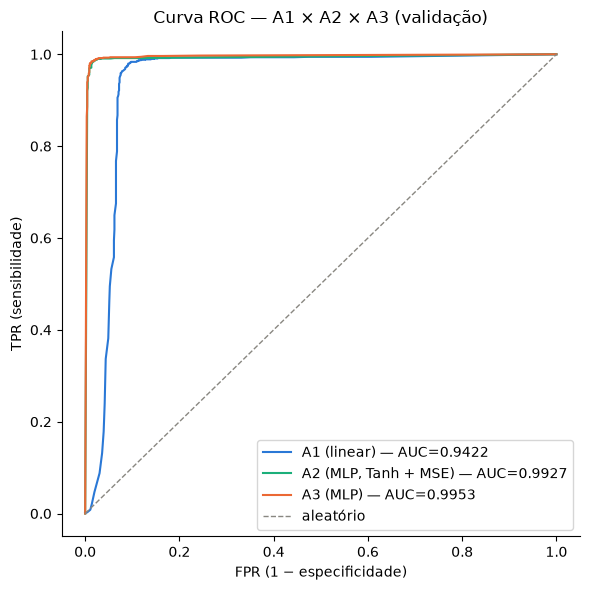

AUC — A1: 0.9422  A2: 0.9927  A3: 0.9953


In [15]:
def curva_roc(y_real, y_prob, n_limiares=200):
    limiares = np.linspace(1, 0, n_limiares)
    tpr_lista, fpr_lista = [], []
    for lim in limiares:
        tp, fp, tn, fn = matriz_confusao(y_real, y_prob, limiar=lim)
        tpr = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
        tpr_lista.append(tpr)
        fpr_lista.append(fpr)
    return np.array(fpr_lista), np.array(tpr_lista)


def auc_trapezio(fpr, tpr):
    return np.trapezoid(tpr, fpr)


fpr_a1, tpr_a1 = curva_roc(y_val, prob_a1_val)
fpr_a2, tpr_a2 = curva_roc(y_val, prob_a2_val)
fpr_a3, tpr_a3 = curva_roc(y_val, prob_a3_val)
auc_a1 = auc_trapezio(fpr_a1, tpr_a1)
auc_a2 = auc_trapezio(fpr_a2, tpr_a2)
auc_a3 = auc_trapezio(fpr_a3, tpr_a3)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr_a1, tpr_a1, label=f"A1 (linear) — AUC={auc_a1:.4f}", color="#2a78d6")
ax.plot(fpr_a2, tpr_a2, label=f"A2 (MLP, Tanh + MSE) — AUC={auc_a2:.4f}", color="#1baf7a")
ax.plot(fpr_a3, tpr_a3, label=f"A3 (MLP) — AUC={auc_a3:.4f}", color="#eb6834")
ax.plot([0, 1], [0, 1], color="#898781", linestyle="--", linewidth=1, label="aleatório")
ax.set_xlabel("FPR (1 − especificidade)")
ax.set_ylabel("TPR (sensibilidade)")
ax.set_title("Curva ROC — A1 × A2 × A3 (validação)")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()
print(f"AUC — A1: {auc_a1:.4f}  A2: {auc_a2:.4f}  A3: {auc_a3:.4f}")